# 01 · Market sizing

The top-down figure used here is *US crude output x WTI*. The volume comes from the committed EIA snapshot (`MCRFPUS2`, refreshed weekly by `.github/workflows/eia-refresh.yml`) and the price from FRED WTI; if a year is incomplete the top-down is reported as unavailable, never estimated. Alongside it we build a bottom-up proxy from what companies actually reported in their 10-Ks, read point-in-time by filing date.

In [1]:
import sys, json
sys.path.insert(0, "..")
import pandas as pd
pd.set_option("display.float_format", "{:,.3f}".format)
from IPython.display import Image, Markdown, display

In [2]:
from src.analysis import sizing
res = sizing.compute()
res['topdown_status']

{'available': True,
 'year': 2025,
 'method': 'sum over months of EIA MCRFPUS2 (kb/d) x 1000 x days x mean FRED DCOILWTICO',
 'us_crude_production_bbl': 4986655000.0,
 'us_crude_production_avg_kbd': 13662.068493150686,
 'us_crude_value_usd': 325914605204.91064,
 'eia_as_of': '2026-10-23',
 'caveats': ['Wellhead value at WTI Cushing spot; realized prices differ by grade and basin.',
  'Crude only: excludes natural gas, NGLs and refined products.',
  "Production for recent months is EIA's estimate and is revised in later releases."]}

## Reported revenue by segment ($bn, fiscal year)

In [3]:
pd.DataFrame(res['segment_revenue_usd']).sort_index() / 1e9

,majors,upstream,midstream,refiners,services
2016,339.460,30.375,61.270,223.215,56.779
2017,418.669,37.845,74.433,271.067,68.239
2018,495.278,53.935,89.510,314.580,79.687
2019,448.124,55.028,85.787,326.765,79.163
2020,294.978,40.790,66.915,198.820,58.751
2021,493.933,63.601,111.194,345.436,58.726
2022,738.426,91.148,142.428,523.826,69.544
2023,601.672,71.012,122.504,440.544,81.659
2024,607.122,72.723,129.972,411.898,87.062
2025,580.213,76.439,148.052,387.762,85.625


In [4]:
display(Markdown(f"FY{res['latest_fiscal_year']} total: **${res['total_revenue_latest_usd']/1e9:,.0f}bn**; missing: {', '.join(res['missing_revenue_latest_year']) or 'none'}"))
pd.Series(res['segment_share_latest'], name='share').map('{:.1%}'.format)

FY2025 total: **$1,278bn**; missing: APA

majors       45.4%
upstream      6.0%
midstream    11.6%
refiners     30.3%
services      6.7%
Name: share, dtype: object

## Why this is a proxy, not a market size

In [5]:
for c in res['caveats']:
    print('-', c)

- Revenue is global and consolidated, not US-only.
- Segments double count: refiners' revenue includes crude bought from producers.
- Majors' and refiners' revenue include pass-through product sales, so revenue overstates value added; it measures scale of flows, not market value.
- Survivor universe of 18 names: excludes private producers and acquired/bankrupt names.
- Companies without a standard us-gaap revenue tag are left out, not estimated.


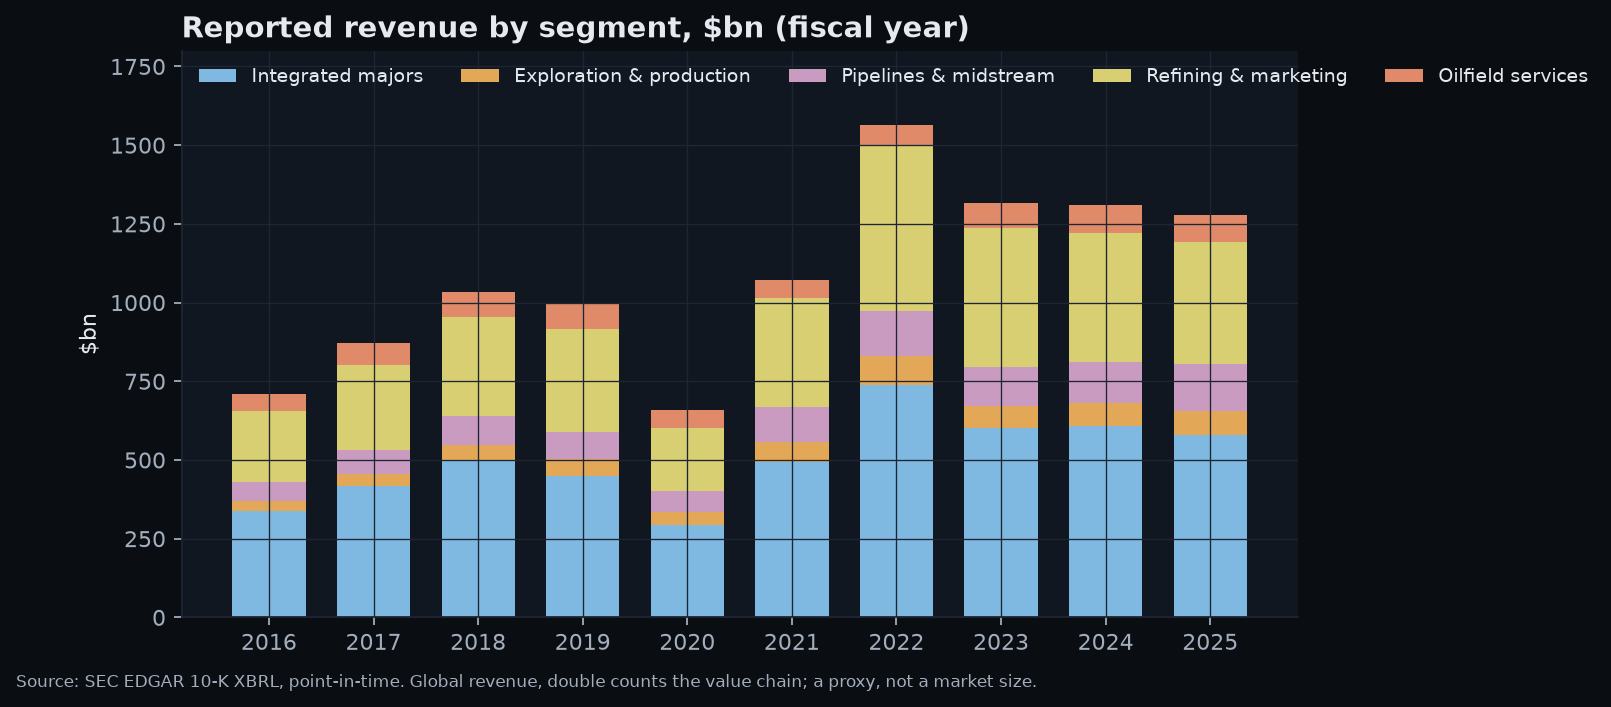

In [6]:
Image('../docs/img/segment_revenue.png')

Revenue is dominated by majors and refiners: their sales include crude and products that pass through at market prices. Upstream and services are small on that measure. Notebook 02 shows they have the higher oil betas. The top-down value of US crude output is above.